# df_semi_analysis.csv 반도체 공정 데이터 분석

`df_semi_analysis.csv` 는 `df_analysis.csv` 에서 **파생 라벨 3개(`Defect`, `두께정상`, `CD정상`)를 뺀 원본형 데이터**입니다.
라벨 없이 연속형 결과 `Target` 을 직접 다루고, **공정 단계(산화·포토·식각·이온주입·열처리)별 기여도**와
**중간 품질지표(thickness, Line_CD)** 를 새로 분석합니다.

1. 데이터 로드 및 기본 점검
2. df_analysis.csv 와의 관계 확인
3. Target 특성 & 변수 정리
4. 공정 단계별 기여도 (Stage attribution)
5. Target 회귀 모델 & 변수 중요도
6. 중간 품질지표(thickness, Line_CD) 분석
7. 해석 가능한 규칙 (Regression Tree)
8. 고위험 공정 조건 & 시각화

## 1. 데이터 로드 및 기본 점검
파일은 UTF-8 인코딩입니다.

In [1]:
import warnings
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

df = pd.read_csv('../data/df_semi_analysis.csv')
print(f'데이터 크기: {df.shape[0]:,}행 × {df.shape[1]}열')
df.head()

데이터 크기: 1,664행 × 42열


,type,Temp_OXid,Vapor,ppm,Pressure,Oxid_time,thickness,resist_target,N2_HMDS,pressure_HMDS,temp_HMDS,temp_HMDS_bake,time_HMDS_bake,spin1,spin2,spin3,photoresist_bake,temp_softbake,time_softbake,Line_CD,UV_type,Wavelength,Resolution,Energy_Exposure,Thin F4,Thin F3,Thin F2,Thin F1,Temp_Etching,Source_Power,Selectivity,Flux60s,Flux90s,Flux160s,Flux480s,Flux840s,input_Energy,Temp_implantation,Furance_Temp,RTA_Temp,Target,Temp_Oxid
0,dry,1214.310,O2,26.69,0.203,120,713.132,1.46994,17.367,15.006,20.001,200.551,90.001,502.391,4017.144,4903.611,5.020,91.918,30.005,41.676,I,365,505.388,109.628,340,1522.0,3644,5732.0,72.651,52.103,1.030,1.500000e+16,1.320000e+17,6.470000e+17,3.010000e+17,6.000000e+17,30795.934,103.433,854,154,141,866.337
1,dry,978.111,O2,30.86,0.217,137,714.295,0.86579,16.090,15.059,19.993,199.835,89.999,507.183,4072.913,4979.082,4.937,90.976,30.005,53.612,H,405,541.732,104.917,265,1513.0,3631,5729.0,70.267,52.004,1.038,1.110000e+16,4.370000e+16,1.040000e+18,3.030000e+17,6.000000e+17,32135.618,105.552,895,156,55,866.337
2,dry,1176.020,O2,31.07,0.218,116,710.114,0.90483,19.026,14.930,19.995,202.118,90.001,501.286,4084.939,5031.989,4.888,91.969,30.006,47.598,I,365,532.200,106.632,411,1568.0,3653,5729.0,71.231,50.846,1.005,1.040000e+16,1.510000e+16,6.470000e+17,2.980000e+17,6.000000e+17,31057.895,102.598,898,152,96,866.337
3,dry,933.443,O2,31.04,0.196,143,710.617,0.42197,18.891,14.947,20.004,194.668,90.000,503.396,4045.078,4969.316,4.933,91.458,30.001,32.843,G,436,537.729,108.785,328,1326.0,3661,5718.0,71.295,51.665,1.025,8.890000e+15,1.020000e+17,3.410000e+17,3.000000e+17,6.000000e+17,32140.566,102.963,879,155,105,866.337
4,wet,1140.600,H2O,31.37,0.215,76,711.632,1.70139,13.788,14.820,19.998,202.192,90.000,501.423,4010.176,5092.407,5.050,94.723,29.988,57.370,H,405,522.143,109.913,219,1451.0,3637,5729.0,72.983,50.787,1.038,1.670000e+16,7.880000e+16,7.260000e+17,3.020000e+17,6.000000e+17,31986.009,101.419,882,155,79,866.337


In [2]:
print(f'결측치 합계 : {df.isna().sum().sum():,}')
print(f'중복 행     : {df.duplicated().sum():,}')
print()
print(f'[컬럼 타입별 개수]')
print(df.dtypes.value_counts().to_string())
print()
print(f'[범주형 변수 분포]')
for c in ['type', 'Vapor', 'UV_type']:
    vc = df[c].value_counts()
    detail = ', '.join(f'{k} {v:,}개 ({v / len(df):.1%})' for k, v in vc.items())
    print(f'  {c:<8s}: {detail}')

결측치 합계 : 0
중복 행     : 0

[컬럼 타입별 개수]
float64    32
int64       7
str         3

[범주형 변수 분포]
  type    : dry 970개 (58.3%), wet 694개 (41.7%)
  Vapor   : O2 970개 (58.3%), H2O 694개 (41.7%)
  UV_type : G 613개 (36.8%), H 554개 (33.3%), I 497개 (29.9%)


In [3]:
desc = df.describe().T
desc['count'] = desc['count'].astype(int)
desc['nunique'] = df.nunique()
desc['cv%'] = desc['std'] / desc['mean'] * 100

# 지수 표기 대신 천 단위 콤마 + 소수점 4자리 (count·nunique 는 정수)
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(desc)

,count,mean,std,min,25%,50%,75%,max,nunique,cv%
Temp_OXid,1664,"1,067.9252",150.1664,862.0110,888.4198,"1,071.6750","1,190.9800","1,311.2300",1616,14.0615
ppm,1664,33.3827,8.1218,21.0700,25.5300,33.6000,39.5100,49.9100,496,24.3295
Pressure,1664,0.2108,0.0092,0.1800,0.2040,0.2120,0.2170,0.2290,46,4.3842
Oxid_time,1664,99.0469,72.6014,8.0000,31.0000,86.0000,148.0000,291.0000,197,73.3001
thickness,1664,711.1780,7.8135,681.4350,707.0610,711.7125,715.5640,737.4020,825,1.0987
resist_target,1664,1.1920,0.4156,0.0544,0.8824,1.1138,1.4891,2.3943,830,34.8621
N2_HMDS,1664,16.0714,2.2415,9.4970,14.7037,16.3090,17.3670,23.5730,777,13.9473
pressure_HMDS,1664,15.0035,0.0778,14.7760,14.9510,15.0030,15.0560,15.2810,303,0.5185
temp_HMDS,1664,19.9995,0.0037,19.9860,19.9970,20.0000,20.0020,20.0120,26,0.0184
temp_HMDS_bake,1664,200.5409,2.8794,191.2090,198.3415,200.5390,202.7900,209.5210,801,1.4358


## 2. df_analysis.csv 와의 관계 확인

In [4]:
ref = pd.read_csv('../data/df_analysis.csv', encoding='cp949')
only_ref = [c for c in ref.columns if c not in df.columns]
only_semi = [c for c in df.columns if c not in ref.columns]
common = [c for c in df.columns if c in ref.columns]
identical = all((df[c].astype(str).values == ref[c].astype(str).values).all() for c in common)

print(f'df_analysis 에만 있는 컬럼     : {only_ref}')
print(f'df_semi_analysis 에만 있는 컬럼: {only_semi}')
print(f'공통 {len(common)}개 컬럼의 행 순서·값 완전 일치: {identical}')

df_analysis 에만 있는 컬럼     : ['Defect', '두께정상', 'CD정상']
df_semi_analysis 에만 있는 컬럼: []
공통 42개 컬럼의 행 순서·값 완전 일치: True


**결론** — 두 파일은 같은 1,664개 웨이퍼, 같은 순서·값입니다. 차이는 df_analysis 에 있는 **파생 라벨 3개뿐**이며,
이 라벨들은 각각 `Target ≥ 195`, `thickness ≥ 700`, `22 ≤ Line_CD ≤ 55` 로 재현됩니다.
따라서 이 노트북은 라벨 대신 **`Target` 자체**와 **공정 단계 구조**에 집중합니다.

In [5]:
recon = pd.DataFrame({
    'Defect':  (df['Target'] >= 195).astype(int),
    '두께정상': np.where(df['thickness'] >= 700, '정상', '비정상'),
    'CD정상':  np.where(df['Line_CD'].between(22, 55), '정상', '비정상'),
})
for c in recon.columns:
    match = (recon[c].astype(str).values == ref[c].astype(str).values).mean()
    print(f'{c:<6s} 재현 일치율: {match:.2%}')

Defect 재현 일치율: 100.00%
두께정상   재현 일치율: 100.00%
CD정상   재현 일치율: 100.00%


## 3. Target 특성 & 변수 정리

In [6]:
t = df['Target']
print(f'Target dtype   : {t.dtype} (정수 → 카운트형 지표로 추정)')
print(f'평균 / 분산     : {t.mean():.1f} / {t.var():,.1f}  (분산 ≫ 평균 → 과산포)')
print(f'왜도            : {t.skew():.2f}')
print(f'0 값 개수       : {(t == 0).sum()}')
for q in [0.5, 0.9, 0.95, 0.99]:
    print(f'  {q:.0%} 분위수   : {t.quantile(q):,.1f}')
print(f'Target ≥ 195 비율: {(t >= 195).mean():.2%}')

Target dtype   : int64 (정수 → 카운트형 지표로 추정)
평균 / 분산     : 102.5 / 3,847.4  (분산 ≫ 평균 → 과산포)
왜도            : 2.08
0 값 개수       : 2
  50% 분위수   : 94.0
  90% 분위수   : 173.7
  95% 분위수   : 213.8
  99% 분위수   : 336.0
Target ≥ 195 비율: 7.27%


In [7]:
const_cols = [c for c in df.columns if df[c].nunique() == 1]
print(f'상수 컬럼: {const_cols}')
print()
print(f'[type × Vapor]')
print(pd.crosstab(df['type'], df['Vapor']))
print()
print(f'[UV_type × Wavelength]')
print(pd.crosstab(df['UV_type'], df['Wavelength']))

상수 컬럼: ['Flux840s', 'Temp_Oxid']

[type × Vapor]
Vapor  H2O   O2
type           
dry      0  970
wet    694    0

[UV_type × Wavelength]
Wavelength  365  405  436
UV_type                  
G             0    0  613
H             0  554    0
I           497    0    0


In [8]:
DROP = ['Target',                 # 목표변수
        'Flux840s', 'Temp_Oxid',  # 상수
        'Vapor', 'Wavelength']    # type / UV_type 과 1:1 중복

X = df.drop(columns=DROP).copy()
X['type'] = (X['type'] == 'wet').astype(int)
X['UV_type'] = X['UV_type'].map({'G': 436, 'H': 405, 'I': 365})   # 노광 파장(nm)으로 수치화
X = X.astype(float)
y = df['Target']

STAGES = {
    '산화':     ['type', 'Temp_OXid', 'ppm', 'Pressure', 'Oxid_time', 'thickness'],
    '포토':     ['resist_target', 'N2_HMDS', 'pressure_HMDS', 'temp_HMDS', 'temp_HMDS_bake', 'time_HMDS_bake',
                 'spin1', 'spin2', 'spin3', 'photoresist_bake', 'temp_softbake', 'time_softbake', 'Line_CD',
                 'UV_type', 'Resolution', 'Energy_Exposure'],
    '식각':     ['Thin F4', 'Thin F3', 'Thin F2', 'Thin F1', 'Temp_Etching', 'Source_Power', 'Selectivity'],
    '이온주입': ['Flux60s', 'Flux90s', 'Flux160s', 'Flux480s', 'input_Energy', 'Temp_implantation'],
    '열처리':   ['Furance_Temp', 'RTA_Temp'],
}
assert sorted(sum(STAGES.values(), [])) == sorted(X.columns)
print(f'입력 X: {X.shape[0]:,}행 × {X.shape[1]}열')
for st, cols in STAGES.items():
    print(f'  {st:<4s} {len(cols):2d}개 변수')

입력 X: 1,664행 × 37열
  산화    6개 변수
  포토   16개 변수
  식각    7개 변수
  이온주입  6개 변수
  열처리   2개 변수


## 4. 공정 단계별 기여도 (Stage attribution)
- **단독 R²**: 해당 단계 변수만으로 Target 을 얼마나 설명하는지
- **제거 시 ΔR²**: 전체 모델에서 해당 단계를 빼면 얼마나 떨어지는지 (다른 단계로 대체 불가능한 고유 정보)

In [9]:
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict, train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV, PoissonRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error

kf = KFold(5, shuffle=True, random_state=0)
def hgb(**kw):
    return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0, **kw)

full_r2 = cross_val_score(hgb(), X, y, cv=kf, scoring='r2').mean()
rows = []
for st, cols in STAGES.items():
    alone = cross_val_score(hgb(), X[cols], y, cv=kf, scoring='r2').mean()
    without = cross_val_score(hgb(), X.drop(columns=cols), y, cv=kf, scoring='r2').mean()
    rows.append((st, len(cols), alone, without - full_r2))
stage_tbl = pd.DataFrame(rows, columns=['단계', '변수 수', '단독 R2', '제거 시 ΔR2']).set_index('단계')

print(f'전체 모델 CV R2 = {full_r2:.3f}')
print()
print(f'[공정 단계별 기여도]')
print(stage_tbl.round(3))

전체 모델 CV R2 = 0.732

[공정 단계별 기여도]
      변수 수  단독 R2  제거 시 ΔR2
단계                         
산화       6  0.316    -0.017
포토      16  0.511    -0.012
식각       7  0.685    -0.143
이온주입     6  0.492     0.004
열처리      2  0.117    -0.000


**해석** — 식각 단계(Thin F1~F4 등)만으로 R² ≈ 0.69 를 설명하고, 빼면 R² 가 0.14 떨어지는 **유일하게 대체 불가능한 단계**입니다.
이온주입·열처리는 단독 R² 가 있어도 제거해도 성능 변화가 없어, 다른 단계 변수와 겹치는 정보만 가진 것으로 보입니다.

## 5. Target 회귀 모델 & 변수 중요도

In [10]:
reg_models = {
    'Ridge':           make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))),
    'Poisson GLM':     make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-3, max_iter=2000)),
    'HistGB (MSE)':    hgb(),
    'HistGB (Poisson)': hgb(loss='poisson'),
}
for name, m in reg_models.items():
    p = cross_val_predict(m, X, y, cv=kf)
    print(f'{name:17s} R2={r2_score(y, p):.3f}  MAE={mean_absolute_error(y, p):.1f}')

Ridge             R2=0.557  MAE=28.8
Poisson GLM       R2=0.604  MAE=27.2


HistGB (MSE)      R2=0.735  MAE=17.2


HistGB (Poisson)  R2=0.721  MAE=17.6


In [11]:
# Permutation importance (hold-out 25%)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0)
model = hgb().fit(Xtr, ytr)
pi = permutation_importance(model, Xte, yte, n_repeats=15, random_state=0, scoring='r2')
imp = pd.Series(pi.importances_mean, X.columns).sort_values(ascending=False)
stage_of = {c: st for st, cols in STAGES.items() for c in cols}

print(f'[Permutation importance 상위 10 (ΔR2)]')
for c, v in imp.head(10).items():
    print(f'  {c:<14s} {stage_of[c]:<4s} {v:.4f}')

[Permutation importance 상위 10 (ΔR2)]
  Thin F2        식각   0.5569
  Thin F4        식각   0.3432
  ppm            산화   0.0792
  Thin F3        식각   0.0595
  Temp_OXid      산화   0.0267
  Pressure       산화   0.0213
  Line_CD        포토   0.0131
  Temp_Etching   식각   0.0099
  Resolution     포토   0.0096
  thickness      산화   0.0083


In [12]:
# Thin F2 × Thin F4 3분위 조합별 Target 평균
f2 = pd.qcut(df['Thin F2'], 3, labels=['F2 하', 'F2 중', 'F2 상'])
f4 = pd.qcut(df['Thin F4'], 3, labels=['F4 하', 'F4 중', 'F4 상'])
heat = pd.crosstab(f2, f4, df['Target'], aggfunc='mean')
print(f'[Thin F2 × Thin F4 조합별 Target 평균]')
print(heat.round(1))
print()
ct = pd.crosstab(df['type'], df['UV_type'], df['Target'], aggfunc='mean')
p_uv = stats.kruskal(*[g['Target'] for _, g in df.groupby('UV_type')]).pvalue
p_type = stats.mannwhitneyu(*[g['Target'] for _, g in df.groupby('type')]).pvalue
print(f'[type × UV_type 조합별 Target 평균]  (UV_type Kruskal p={p_uv:.2e}, type Mann-Whitney p={p_type:.3f})')
print(ct.round(1))

[Thin F2 × Thin F4 조합별 Target 평균]
Thin F4   F4 하   F4 중   F4 상
Thin F2                     
F2 하      54.2   78.2   92.1
F2 중      78.0  101.5  124.8
F2 상     106.7  120.1  163.5

[type × UV_type 조합별 Target 평균]  (UV_type Kruskal p=6.58e-07, type Mann-Whitney p=0.054)
UV_type      G      H      I
type                        
dry       92.6  125.9  112.8
wet      102.6   99.4   91.1


## 6. 중간 품질지표(thickness, Line_CD) 분석
산화 결과인 `thickness`, 포토 결과인 `Line_CD` 가 어떤 변수로 결정되고, 최종 Target 과 어떤 관계인지 확인합니다.

In [13]:
ox_in = ['type', 'Temp_OXid', 'ppm', 'Pressure', 'Oxid_time']
ph_in = [c for c in STAGES['포토'] if c != 'Line_CD']
cases = [
    ('thickness', '산화 입력 5개', ox_in),
    ('thickness', '전체 변수',     [c for c in X.columns if c != 'thickness']),
    ('Line_CD',   '포토 입력 15개', ph_in),
    ('Line_CD',   '전체 변수',      [c for c in X.columns if c != 'Line_CD']),
]
print(f'[중간 품질지표 예측력 (HistGB CV R2)]')
for tgt, label, cols in cases:
    r = cross_val_score(hgb(), X[cols], df[tgt], cv=kf, scoring='r2').mean()
    print(f'  {tgt:<9s} ~ {label:<12s} R2 = {r:.3f}')

[중간 품질지표 예측력 (HistGB CV R2)]


  thickness ~ 산화 입력 5개     R2 = 0.372


  thickness ~ 전체 변수        R2 = 0.611


  Line_CD   ~ 포토 입력 15개    R2 = 0.751


  Line_CD   ~ 전체 변수        R2 = 0.838


In [14]:
sp = df.select_dtypes('number').drop(columns=['Flux840s', 'Temp_Oxid']).corr(method='spearman')
for tgt in ['thickness', 'Line_CD']:
    top = sp[tgt].drop([tgt, 'Target']).sort_values(key=abs, ascending=False).head(6)
    print(f'[{tgt} 와 Spearman 상관 상위 6]')
    for c, v in top.items():
        print(f'  {c:<17s} {v:+.3f}')
    print()

[thickness 와 Spearman 상관 상위 6]
  Temp_Etching      +0.433
  Pressure          +0.367
  temp_softbake     -0.251
  input_Energy      +0.230
  Flux90s           -0.217
  spin2             -0.198

[Line_CD 와 Spearman 상관 상위 6]
  Temp_implantation +0.240
  Thin F2           +0.232
  Selectivity       +0.231
  Source_Power      +0.229
  Energy_Exposure   +0.221
  RTA_Temp          +0.209



In [15]:
for c in ['thickness', 'Line_CD']:
    g = df.groupby(pd.qcut(df[c], 5), observed=True)['Target'].agg(['mean', 'median', 'size'])
    print(f'[{c} 5분위 구간별 Target]')
    print(g.round(1))
    print()

[thickness 5분위 구간별 Target]
                     mean  median  size
thickness                              
(681.434, 705.345]   97.9    94.5   334
(705.345, 710.093]   94.5    84.0   333
(710.093, 713.197]   97.0    93.0   331
(713.197, 716.978]   97.1    86.0   333
(716.978, 737.402]  126.2   112.0   333

[Line_CD 5분위 구간별 Target]
                   mean  median  size
Line_CD                              
(4.561, 30.241]    84.7    84.0   333
(30.241, 36.548]   96.6    86.0   333
(36.548, 44.48]   102.3    99.0   333
(44.48, 51.247]   100.2    96.0   332
(51.247, 76.265]  128.9   101.0   333



**해석** — `Line_CD` 는 포토 입력만으로 R² ≈ 0.75 로 잘 예측되지만, `thickness` 는 산화 입력만으로는 R² ≈ 0.37 에 그치고
식각 온도(`Temp_Etching`) 등 후공정 변수와 상관이 더 큽니다. 두 지표 모두 **상위 20% 구간에서만 Target 이 뚜렷이 상승**합니다.

## 7. 해석 가능한 규칙 (Regression Tree)

In [16]:
from sklearn.tree import DecisionTreeRegressor, export_text

for d in [2, 3, 4, 5]:
    r = cross_val_score(DecisionTreeRegressor(max_depth=d, min_samples_leaf=20, random_state=0),
                        X, y, cv=kf, scoring='r2').mean()
    print(f'max_depth={d}  CV R2 = {r:.3f}')

tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=0).fit(X, y)
print()
print(f'[Regression Tree 규칙 (max_depth=3), value = 평균 Target]')
for line in export_text(tree, feature_names=list(X.columns), decimals=2).splitlines():
    print(line)

max_depth=2  CV R2 = 0.319
max_depth=3  CV R2 = 0.410


max_depth=4  CV R2 = 0.451

max_depth=5  CV R2 = 0.477

[Regression Tree 규칙 (max_depth=3), value = 평균 Target]
|--- Thin F2 <= 3666.50
|   |--- Thin F4 <= 203.50
|   |   |--- Thin F2 <= 3639.50
|   |   |   |--- value: [41.48]
|   |   |--- Thin F2 >  3639.50
|   |   |   |--- value: [71.79]
|   |--- Thin F4 >  203.50
|   |   |--- Thin F2 <= 3641.50
|   |   |   |--- value: [81.15]
|   |   |--- Thin F2 >  3641.50
|   |   |   |--- value: [111.14]
|--- Thin F2 >  3666.50
|   |--- ppm <= 22.45
|   |   |--- value: [324.12]
|   |--- ppm >  22.45
|   |   |--- Thin F4 <= 430.00
|   |   |   |--- value: [129.35]
|   |   |--- Thin F4 >  430.00
|   |   |   |--- value: [187.82]


In [17]:
leaf = pd.Series(tree.apply(X), index=df.index, name='leaf')
leaf_tbl = df.groupby(leaf)['Target'].agg(
    n='size', 평균_Target='mean', Target_195이상=lambda v: (v >= 195).mean()
).sort_values('평균_Target', ascending=False)
print(f'[Tree leaf 별 요약]')
print(leaf_tbl.round(3))

[Tree leaf 별 요약]
        n  평균_Target  Target_195이상
leaf                              
9      25    324.120         0.840
12     78    187.821         0.410
11    233    129.352         0.056
7     659    111.137         0.076
6     271     81.155         0.000
4     198     71.788         0.025
3     200     41.480         0.000


## 8. 고위험 공정 조건 & 시각화

In [18]:
conds = {
    '산화온도<900 & F4>458':   (df['Temp_OXid'] < 900) & (df['Thin F4'] > 458),
    'F2>3666.5 & ppm≤22.45':   (df['Thin F2'] > 3666.5) & (df['ppm'] <= 22.45),
    'F4>458 & ppm≤28.45':      (df['Thin F4'] > 458) & (df['ppm'] <= 28.45),
    'F2>3656.5 & F4>458':      (df['Thin F2'] > 3656.5) & (df['Thin F4'] > 458),
    'F2>3666.5':               df['Thin F2'] > 3666.5,
    '전체':                    pd.Series(True, index=df.index),
}
risk = pd.DataFrame({
    'n': {k: m.sum() for k, m in conds.items()},
    '평균_Target': {k: df.loc[m, 'Target'].mean() for k, m in conds.items()},
    'Target≥195 비율': {k: (df.loc[m, 'Target'] >= 195).mean() for k, m in conds.items()},
})
print(f'[고위험 조건별 Target (조건 간 중복 있음)]')
print(risk.round(3))

[고위험 조건별 Target (조건 간 중복 있음)]
                          n  평균_Target  Target≥195 비율
산화온도<900 & F4>458        15    392.600          1.000
F2>3666.5 & ppm≤22.45    25    324.120          0.840
F4>458 & ppm≤28.45       24    306.250          0.917
F2>3656.5 & F4>458      121    199.190          0.455
F2>3666.5               336    157.417          0.196
전체                     1664    102.544          0.073


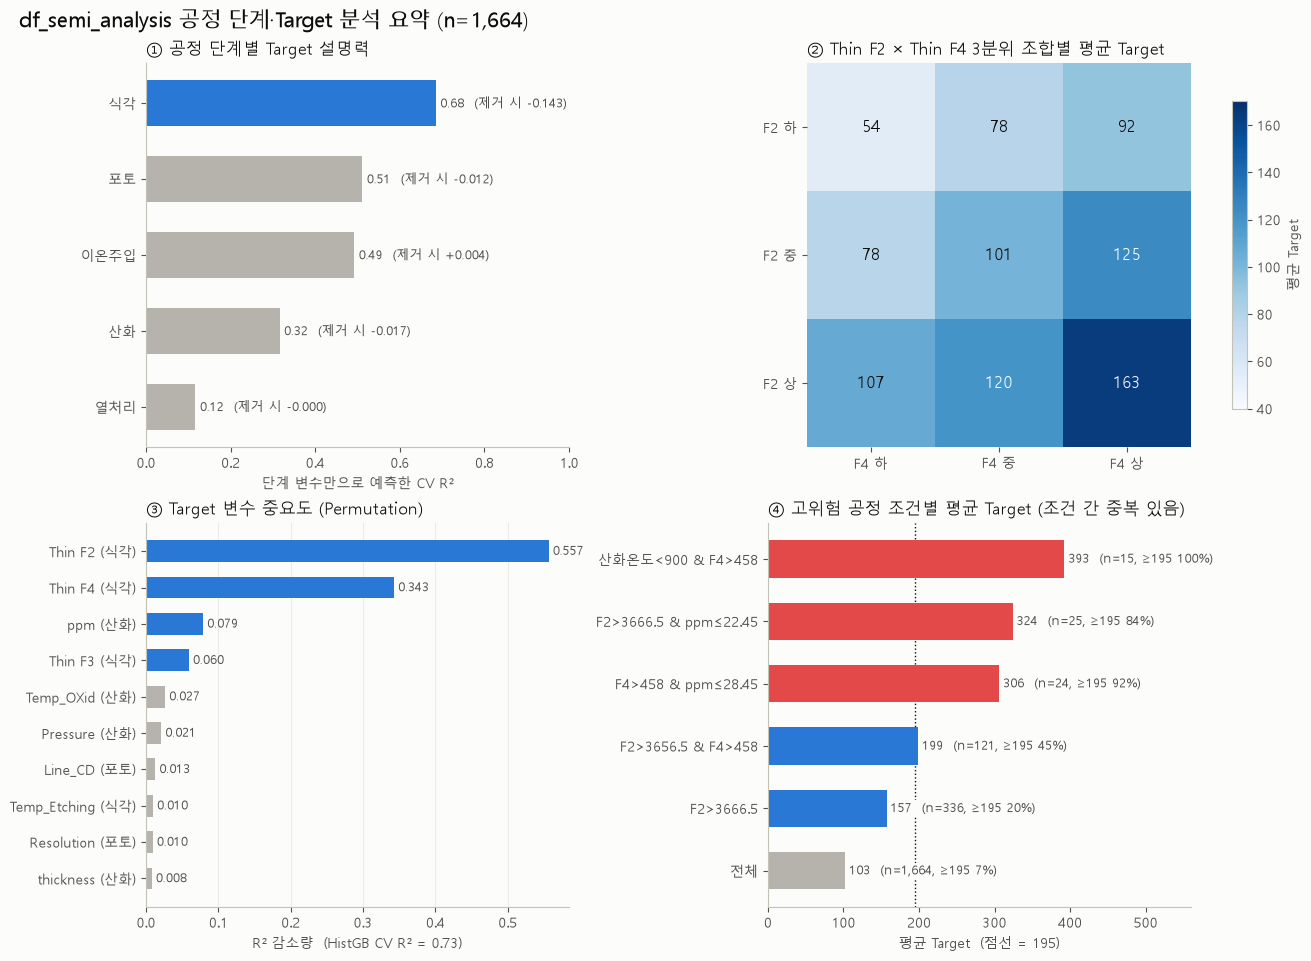

In [19]:
import os
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'font.size': 10,
                     'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb'})
BLUE, ORANGE, RED, GRAY, INK, SUB = '#2a78d6', '#eb6834', '#e34948', '#b5b3ab', '#0b0b0b', '#52514e'

fig, ax = plt.subplots(2, 2, figsize=(13, 9.5), constrained_layout=True)
fig.suptitle('df_semi_analysis 공정 단계·Target 분석 요약 (n=1,664)', fontsize=15, color=INK, x=0.01, ha='left')

# ① 공정 단계별 단독 R²
a = ax[0, 0]; st = stage_tbl.sort_values('단독 R2')
a.barh(st.index, st['단독 R2'], height=0.6, color=[BLUE if i == '식각' else GRAY for i in st.index])
for i, (r2, dlt) in enumerate(zip(st['단독 R2'], st['제거 시 ΔR2'])):
    a.text(r2 + 0.01, i, f'{r2:.2f}  (제거 시 {dlt:+.3f})', va='center', fontsize=9, color=SUB)
a.set_xlim(0, 1); a.set_xlabel('단계 변수만으로 예측한 CV R²')
a.set_title('① 공정 단계별 Target 설명력', loc='left', color=INK)

# ② Thin F2 × F4 히트맵
a = ax[0, 1]
im = a.imshow(heat.values, cmap='Blues', vmin=40, vmax=170)
a.set_xticks(range(3), heat.columns); a.set_yticks(range(3), heat.index)
for i in range(3):
    for j in range(3):
        v = heat.values[i, j]
        a.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=12, color='white' if v > 120 else INK)
a.spines[:].set_visible(False)
a.set_title('② Thin F2 × Thin F4 3분위 조합별 평균 Target', loc='left', color=INK)
fig.colorbar(im, ax=a, shrink=0.8, label='평균 Target')

# ③ 변수 중요도
a = ax[1, 0]; top = imp.head(10)[::-1]
a.barh([f'{c} ({stage_of[c]})' for c in top.index], top.values, height=0.6,
       color=[BLUE if v > 0.05 else GRAY for v in top.values])
for i, v in enumerate(top.values):
    a.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=9, color=SUB)
a.set_xlabel(f'R² 감소량  (HistGB CV R² = {full_r2:.2f})'); a.grid(axis='x', color='#ecebe7'); a.set_axisbelow(True)
a.set_title('③ Target 변수 중요도 (Permutation)', loc='left', color=INK)

# ④ 고위험 조건
a = ax[1, 1]; rk = risk.sort_values('평균_Target')
a.barh(rk.index, rk['평균_Target'], height=0.6,
       color=[RED if v >= 250 else (BLUE if v >= 130 else GRAY) for v in rk['평균_Target']])
for i, (v, n, p) in enumerate(zip(rk['평균_Target'], rk['n'], rk['Target≥195 비율'])):
    a.text(v + 5, i, f'{v:.0f}  (n={n:,}, ≥195 {p:.0%})', va='center', fontsize=9, color=SUB, zorder=3,
           bbox=dict(boxstyle='square,pad=0.15', fc='#fcfcfb', ec='none'))
a.axvline(195, color=INK, lw=1, ls=':', zorder=0); a.set_xlim(0, 560)
a.set_xlabel('평균 Target  (점선 = 195)')
a.set_title('④ 고위험 공정 조건별 평균 Target (조건 간 중복 있음)', loc='left', color=INK)

os.makedirs('output', exist_ok=True)
fig.savefig('output/df_semi_analysis_summary.png', dpi=150)
plt.show()

## 결론 요약
- **데이터 관계**: df_analysis.csv 와 같은 1,664 웨이퍼·같은 값, 파생 라벨 3개(`Defect`, `두께정상`, `CD정상`)만 없음 → 규칙으로 100% 재현
- **Target**: 정수형·과산포(평균 102.5, 분산 3,847), 오른쪽 꼬리(왜도 2.08) — 상위 7.3% 가 195 이상
- **공정 단계 기여도**: 식각 단독 R² 0.69, 제거 시 −0.14 로 **핵심 단계**. 이온주입·열처리는 고유 정보 없음
- **모델**: HistGB R² ≈ 0.73 (MAE 17) ≫ Poisson GLM 0.60 > Ridge 0.56 → 비선형·임계값 구조
- **핵심 변수**: Thin F2, Thin F4 ≫ ppm, Thin F3, Temp_OXid, Pressure. F2·F4 모두 상위 3분위면 평균 Target 164 (하위 조합 54의 3배)
- **중간지표**: Line_CD 는 포토 입력으로 R² 0.75 예측, thickness 는 산화 입력만으로는 0.37 — 두 지표 모두 상위 20% 구간에서 Target 상승
- **고위험 조건**: 산화온도<900 & F4>458 → 평균 393 (n=15, 전부 ≥195) · **F2>3666.5 & ppm≤22.45 → 평균 324 (n=25, 84% ≥195)** · F4>458 & ppm≤28.45 → 평균 306 (n=24)
- 관측 데이터 기반 상관관계이므로 인과 확정은 DOE 검증 필요